# OASIS INFOBYTE INTERNSHIP
## LEVEL 2
# TASK 1 - Predicting House Prices with Linear Regression

**Internship Organization:** Oasis Infobyte

**Type:** Data Analytics

---

## 1. Objective

Build and evaluate a linear regression model that predicts house prices based on features such as area, location, number of rooms, and age. Develop end-to-end skills from data cleaning through to model interpretation.

## 2. Tech Stack

- Python
- Pandas
- Scikit-learn
- Matplotlib
- Seaborn
- Jupyter Notebook

## 3. Project Description

This project focuses on predicting house prices using a Linear Regression model. The housing dataset is analyzed to understand the relationship between property characteristics and house prices.

The project covers data exploration, data cleaning, feature selection, categorical encoding, model training, prediction, evaluation, and model interpretation.

## 4. Dataset Information

- **Dataset Name:** Housing.csv
- **Total Records:** 545
- **Original Columns:** 13
- **Target Variable:** price

### Numerical Features
- area
- bedrooms
- bathrooms
- stories
- parking

### Categorical Features
- mainroad
- guestroom
- basement
- hotwaterheating
- airconditioning
- prefarea
- furnishingstatus

## 5. Feature Checklist

- [x] Load dataset and perform EDA: null check, descriptive statistics, and distribution of the target variable (price).
- [x] Feature selection discussion: identify which features are likely predictors and explain reasoning in a Markdown cell.
- [x] Handle missing values and encode categorical features using One-Hot Encoding.
- [x] Create a correlation heatmap and identify features most correlated with house price.
- [x] Split the dataset into training and testing sets (80/20).
- [x] Train a Linear Regression model using Scikit-learn.
- [x] Evaluate the model using Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R² Score.
- [x] Create a scatter plot comparing actual prices vs. predicted prices.
- [x] Create a residual plot to check whether residuals are randomly distributed.
- [x] Perform coefficient analysis to identify features with the highest positive and negative coefficients.
- [ ] Bonus: Compare Linear Regression against a Ridge or Lasso regularised model.

## 6. Project Workflow

1. Import required Python libraries.
2. Load the housing dataset.
3. Inspect dataset structure and descriptive statistics.
4. Perform Exploratory Data Analysis (EDA).
5. Check missing values and duplicate records.
6. Analyze numerical and categorical features.
7. Perform feature selection.
8. Apply One-Hot Encoding.
9. Create a correlation heatmap.
10. Split data into training and testing sets.
11. Train the Linear Regression model.
12. Generate house price predictions.
13. Evaluate model performance.
14. Visualize actual vs. predicted prices.
15. Perform residual analysis.
16. Analyze model coefficients.
17. Save the trained model using Joblib.

## 7. Expected Outcome

Develop a Linear Regression model capable of predicting house prices based on property characteristics. Evaluate its performance using regression metrics and understand how different features influence predicted house prices.

## 8. Final Project Conclusion

The project demonstrates the practical application of Linear Regression for house price prediction. It covers the complete machine learning workflow, from data exploration and preprocessing to model training, evaluation, and interpretation.

The trained model provides a useful baseline for predicting house prices. Further improvements using feature engineering and regularised regression models may improve prediction performance.

## 9. Self-Sourcing Guidelines

- Search for house price prediction datasets on Kaggle.
- Refer to the Ames Housing Dataset and House Prices: Advanced Regression Techniques competition dataset as suggested alternatives.
- Refer to Python Linear Regression tutorials.
- Consult Scikit-learn documentation for LinearRegression, mean_squared_error, and r2_score.

In [129]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

# Set visualization style
sns.set_theme(style="whitegrid")

# Display settings
pd.set_option('display.max_columns', None)

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [130]:
df = pd.read_csv("Housing.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [131]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [132]:
df.tail()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished
544,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished


In [133]:
df.sample(5)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
428,3325000,4040,2,1,1,yes,no,no,no,no,1,no,unfurnished
211,4900000,12900,3,1,1,yes,no,no,no,no,2,no,furnished
465,3045000,3800,2,1,1,yes,no,no,no,no,0,no,unfurnished
242,4550000,3640,3,1,2,yes,no,no,no,yes,0,no,furnished
146,5600000,10500,2,1,1,yes,no,no,no,no,1,no,semi-furnished


In [134]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 545
Number of columns: 13


In [135]:
print(df.columns.tolist())

['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


In [136]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 69.2 KB


In [137]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [138]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [139]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [140]:
for column in df.columns:
    print(column, ":", df[column].nunique())

price : 219
area : 284
bedrooms : 6
bathrooms : 4
stories : 4
mainroad : 2
guestroom : 2
basement : 2
hotwaterheating : 2
airconditioning : 2
parking : 4
prefarea : 2
furnishingstatus : 3


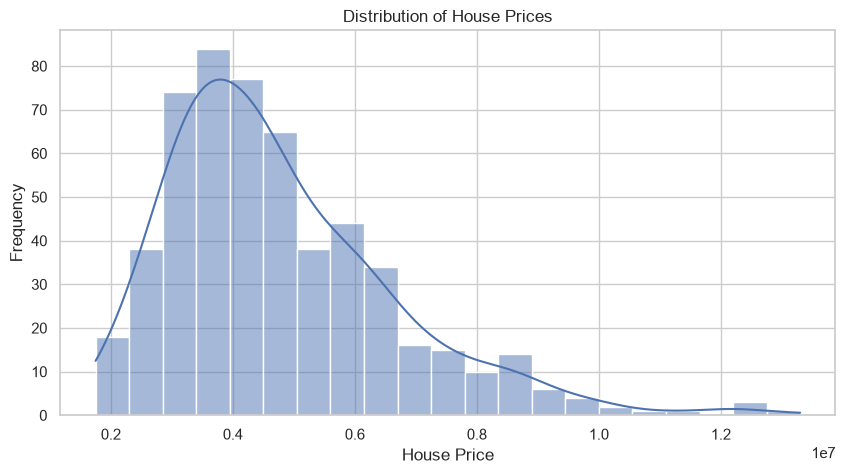

In [141]:
plt.figure(figsize=(10, 5))

sns.histplot(df['price'], kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.show()

**Observation:**

The histogram shows the distribution of house prices in the dataset. Most houses are concentrated between approximately 3 million and 5 million, with the highest frequency around 3.5–4 million. The distribution is positively skewed (right-skewed), indicating that a smaller number of houses have significantly higher prices. Some properties have prices exceeding 10 million, forming a long tail on the right side of the distribution.

**Conclusion:** House prices are not evenly distributed, as most properties fall within a moderate price range while a few have considerably higher values.

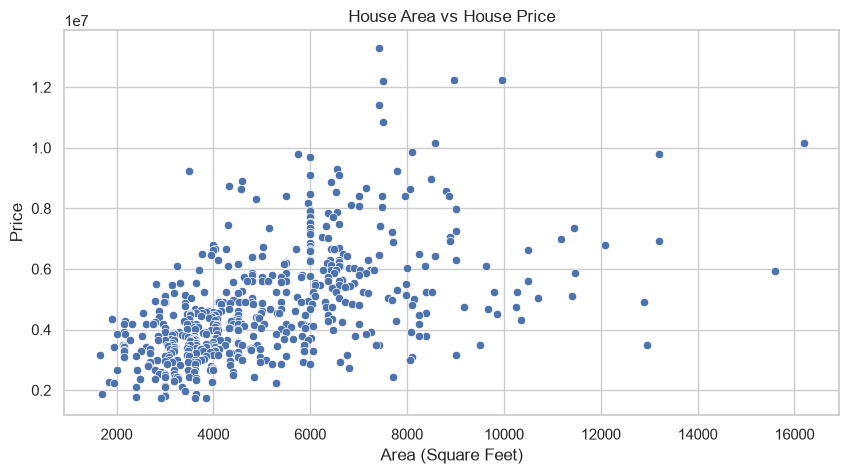

In [142]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='area',
    y='price'
)

plt.title("House Area vs House Price")
plt.xlabel("Area (Square Feet)")
plt.ylabel("Price")

plt.show()

**Observation:**

The scatter plot shows a positive relationship between house area and house price. Generally, houses with larger areas tend to have higher prices. Most properties are concentrated between approximately 2,500 and 7,000 square feet, with prices mainly ranging from 2 million to 6 million. Some outliers with very large areas and varying prices are also visible. This indicates that house area is an important factor influencing property prices.

**Conclusion:** House area plays an important role in determining property prices, although other factors also influence the final selling price.

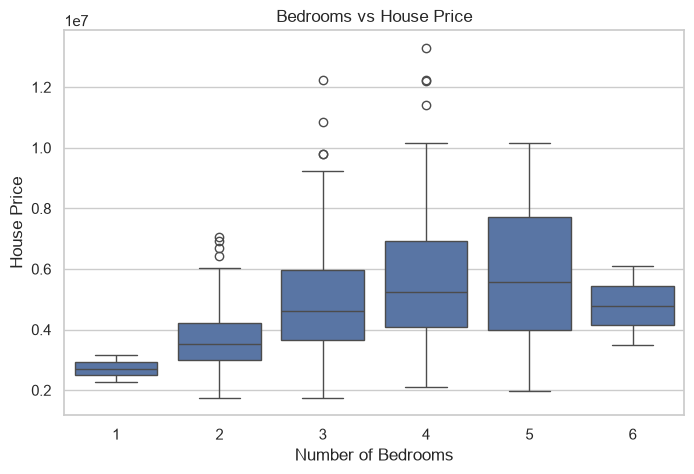

In [143]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='bedrooms',
    y='price'
)

plt.title("Bedrooms vs House Price")
plt.xlabel("Number of Bedrooms")
plt.ylabel("House Price")

plt.show()

**Observation:**

The boxplot illustrates the relationship between the number of bedrooms and house prices. The median house price generally increases as the number of bedrooms increases from 1 to 5. Five-bedroom houses show the highest median price among the categories. However, six-bedroom houses have a comparatively lower median price than four- and five-bedroom houses. The graph also shows variations in price distributions and several high-price outliers, especially in the 3- and 4-bedroom categories.

**Conclusion:** The number of bedrooms influences house prices, but the relationship is not always linear. Other property features also contribute to price variations.

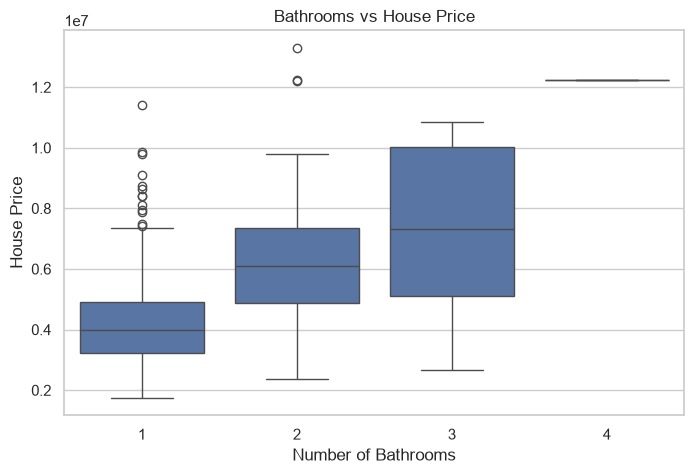

In [144]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='bathrooms',
    y='price'
)

plt.title("Bathrooms vs House Price")
plt.xlabel("Number of Bathrooms")
plt.ylabel("House Price")

plt.show()

**Observation:**

The boxplot illustrates the relationship between the number of bathrooms and house prices. The median price generally increases from approximately 4 million for one-bathroom houses to 7.3 million for three-bathroom houses. The four-bathroom category shows a price of approximately 12.2 million, but it appears to contain only one property. Several high-price outliers are also visible in the one- and two-bathroom categories.

**Conclusion:** The number of bathrooms appears to have a positive relationship with house prices. However, the four-bathroom category has very limited data, so further conclusions about this category cannot be made reliably.

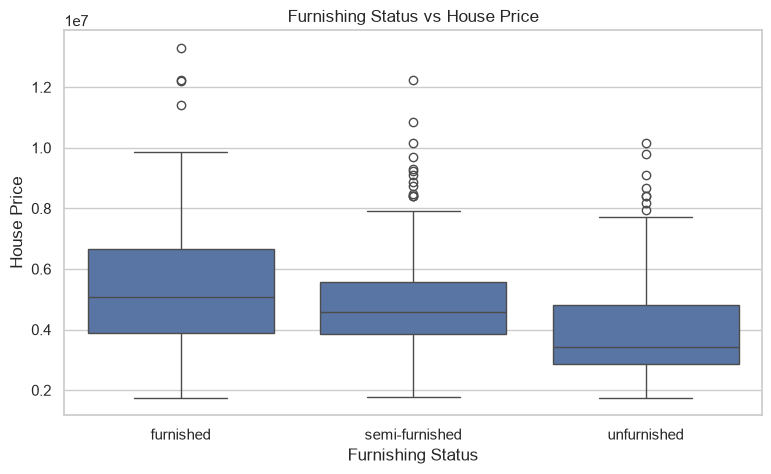

In [145]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='furnishingstatus',
    y='price'
)

plt.title("Furnishing Status vs House Price")
plt.xlabel("Furnishing Status")
plt.ylabel("House Price")

plt.show()

**Observation:**

The boxplot compares house prices across three furnishing categories: furnished, semi-furnished and unfurnished. Furnished houses have the highest median price of approximately 5.1 million, followed by semi-furnished houses at approximately 4.5 million. Unfurnished houses have the lowest median price of approximately 3.4 million. The graph also shows variations in price distributions and several high-price outliers across all three categories.

**Conclusion:** Furnishing status appears to influence house prices, with furnished properties generally having higher median prices than semi-furnished and unfurnished properties.

In [146]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

correlation

,price,area,bedrooms,bathrooms,stories,parking
price,1.000000,0.535997,0.366494,0.517545,0.420712,0.384394
area,0.535997,1.000000,0.151858,0.193820,0.083996,0.352980
bedrooms,0.366494,0.151858,1.000000,0.373930,0.408564,0.139270
bathrooms,0.517545,0.193820,0.373930,1.000000,0.326165,0.177496
stories,0.420712,0.083996,0.408564,0.326165,1.000000,0.045547
parking,0.384394,0.352980,0.139270,0.177496,0.045547,1.000000


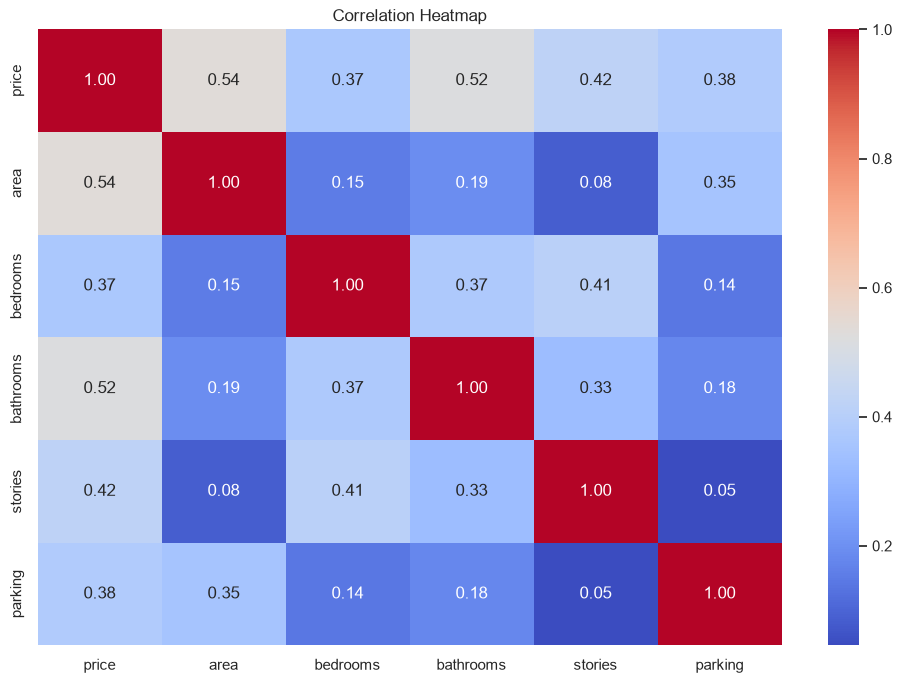

In [147]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

**Observation:**

The correlation heatmap illustrates the relationships between numerical variables in the housing dataset. Area has the highest positive correlation with house price (0.54), followed by bathrooms (0.52), stories (0.42), parking (0.38) and bedrooms (0.37). These values indicate that all numerical features have positive relationships with house prices. Area and bathrooms show comparatively stronger correlations with the target variable.

**Conclusion:** Area and bathrooms appear to be important numerical features for house price prediction. However, correlation does not necessarily imply causation, and other property characteristics may also influence house prices.

## Feature Selection Discussion

The target variable for this project is `price`. The remaining features are considered potential predictors of house prices.

Based on the correlation heatmap, the numerical features with the strongest positive correlations with house price are:

1. Area: 0.54
2. Bathrooms: 0.52
3. Stories: 0.42
4. Parking: 0.38
5. Bedrooms: 0.37

Categorical features such as main road access, guestroom availability, basement, hot water heating, air conditioning, preferred area and furnishing status are also included because they may influence house prices.

Therefore, both numerical and categorical features are selected as input variables for the Linear Regression model.

**Conclusion:** Area and bathrooms show the strongest numerical correlations with house price. Other property characteristics may also contribute to price prediction.

**Note:** Correlation indicates association and does not necessarily imply causation.

In [148]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [149]:
print("Duplicates before removal:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after removal:", df.duplicated().sum())

Duplicates before removal: 0
Duplicates after removal: 0


In [150]:
# Identify numerical columns
numerical_columns = df.select_dtypes(
    include=['number']
).columns

# Identify categorical columns
categorical_columns = df.select_dtypes(
    include=['object', 'str']
).columns

print("Numerical Columns:")
print(numerical_columns.tolist())

print("\nCategorical Columns:")
print(categorical_columns.tolist())

Numerical Columns:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking']

Categorical Columns:
['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


In [151]:
df_encoded = pd.get_dummies(
    df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

df_encoded.head()

,price,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,2,1,0,0,0,1,1,0,0
1,12250000,8960,4,4,4,3,1,0,0,0,1,0,0,0
2,12250000,9960,3,2,2,2,1,0,1,0,0,1,1,0
3,12215000,7500,4,2,2,3,1,0,1,0,1,1,0,0
4,11410000,7420,4,1,2,2,1,1,1,0,1,0,0,0


Categorical variables were converted into numerical representations using One-Hot Encoding. This makes the dataset suitable for machine learning algorithms while avoiding unnecessary numerical ordering between categories.

In [152]:
X = df_encoded.drop('price', axis=1)

y = df_encoded['price']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Input Features Shape: (545, 13)
Target Variable Shape: (545,)


In [153]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (436, 13)
Testing Data: (109, 13)


The dataset was divided into 80% training data and 20% testing data. The training dataset will be used to train the machine learning model, while the testing dataset will evaluate its performance on unseen records.

In [154]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [155]:
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [156]:
# Feature Coefficient Analysis

coefficient_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_
})

coefficient_df = coefficient_df.sort_values(
    by='Coefficient',
    ascending=False
)

print("Feature Coefficient Analysis:")
display(coefficient_df)

print("\nHighest Positive Coefficient:")
display(coefficient_df.iloc[0])

print("\nHighest Negative Coefficient:")
display(coefficient_df.iloc[-1])

Feature Coefficient Analysis:


,Feature,Coefficient
2,bathrooms,1.094445e+06
9,airconditioning_yes,7.914267e+05
8,hotwaterheating_yes,6.846499e+05
10,prefarea_yes,6.298906e+05
3,stories,4.074766e+05
7,basement_yes,3.902512e+05
5,mainroad_yes,3.679199e+05
6,guestroom_yes,2.316100e+05
4,parking,2.248419e+05
1,bedrooms,7.677870e+04



Highest Positive Coefficient:


Feature             bathrooms
Coefficient    1094444.786101
Name: 2, dtype: object


Highest Negative Coefficient:


Feature        furnishingstatus_unfurnished
Coefficient                  -413645.062228
Name: 12, dtype: object

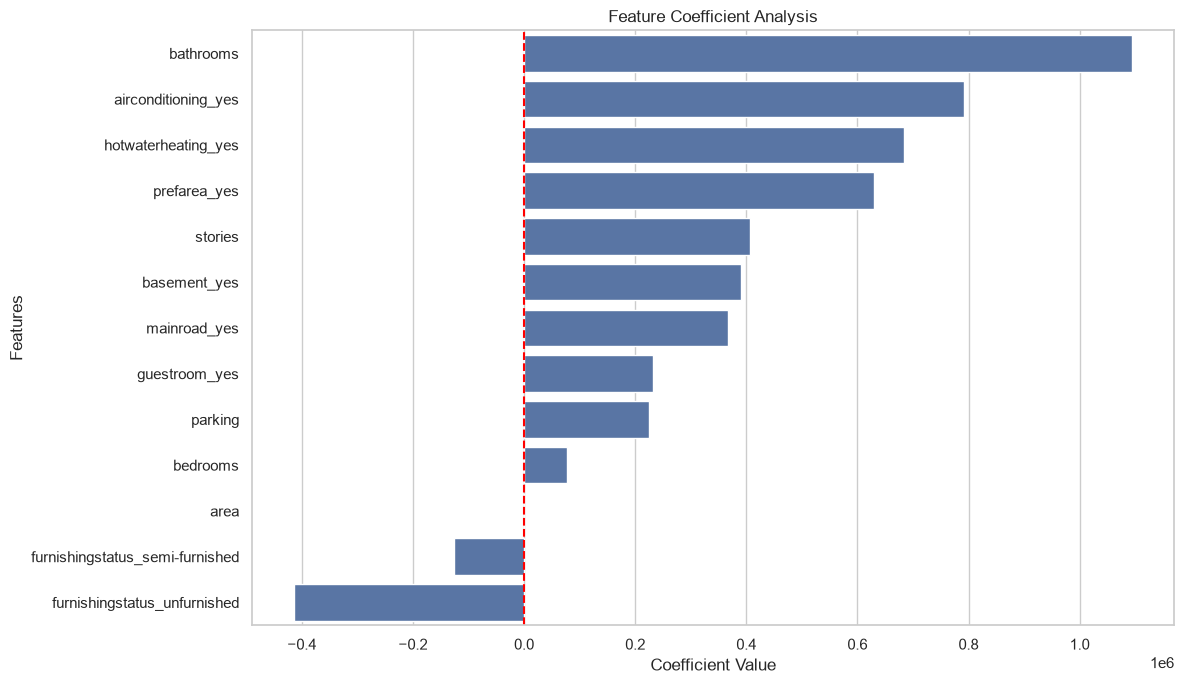

In [157]:
# Feature Coefficient Visualization

plt.figure(figsize=(12, 7))

sns.barplot(
    data=coefficient_df,
    x='Coefficient',
    y='Feature'
)

plt.axvline(
    x=0,
    color='red',
    linestyle='--'
)

plt.title("Feature Coefficient Analysis")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

## Coefficient Analysis - Observation

The coefficient analysis explains how different features are associated with predicted house prices.

- Positive coefficients indicate a positive association with predicted prices, keeping other features constant.
- Negative coefficients indicate a negative association with predicted prices.
- Categorical feature coefficients represent differences relative to their reference categories.

The coefficient table identifies the features with the highest positive and negative coefficients.

**Conclusion:** Coefficient analysis helps understand the direction of the relationship between input features and predicted house prices.

**Note:** Coefficient magnitudes depend on feature scales and should not be treated as directly comparable feature-importance scores.

In [158]:
y_pred = model.predict(X_test)

print("Predicted House Prices:")
print(y_pred[:10])

Predicted House Prices:
[5164653.90033967 7224722.29802167 3109863.24240338 4612075.32722559
 3294646.25725955 3532275.09556558 5611774.56836476 6368145.98732718
 2722856.95689985 2629405.61585782]


In [159]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,4060000,5.164654e+06
1,6650000,7.224722e+06
2,3710000,3.109863e+06
3,6440000,4.612075e+06
4,2800000,3.294646e+06
5,4900000,3.532275e+06
6,5250000,5.611775e+06
7,4543000,6.368146e+06
8,2450000,2.722857e+06
9,3353000,2.629406e+06


In [160]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 970043.4039201635
Mean Squared Error: 1754318687330.663
Root Mean Squared Error: 1324506.9600914384
R2 Score: 0.6529242642153186


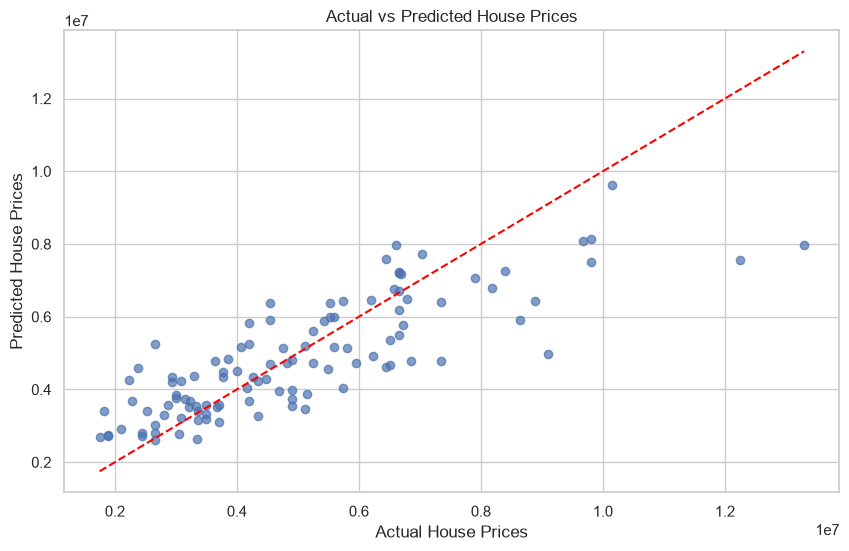

In [161]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.show()

**Observation:**

The scatter plot compares actual house prices with the prices predicted by the Linear Regression model. The red dashed line represents perfect predictions, where actual and predicted prices are equal. Many data points are relatively close to this line, indicating reasonable prediction performance. However, some points are significantly distant from the line, showing prediction errors. Several higher-priced properties are also underestimated by the model.

**Conclusion:** The Linear Regression model captures the general trend in house prices, but its predictions are not perfectly accurate and may be improved through further model optimization.

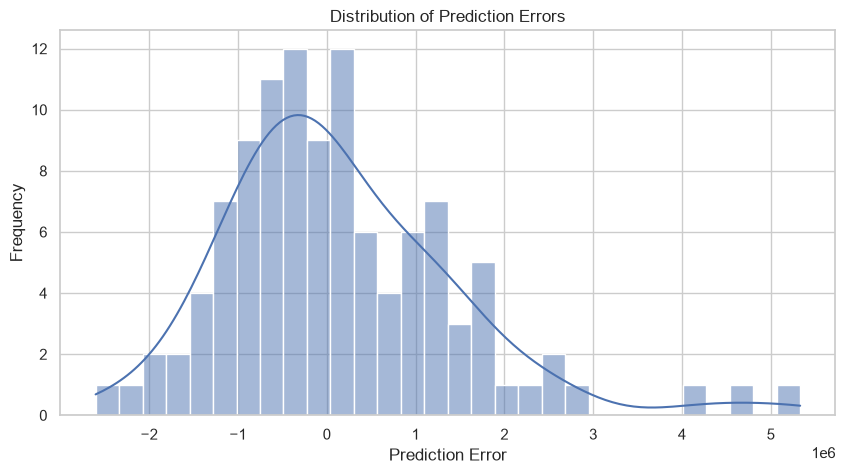

In [162]:
residuals = y_test - y_pred

plt.figure(figsize=(10, 5))

sns.histplot(residuals, kde=True, bins=30)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()

**Observation:**

The histogram shows the distribution of prediction errors calculated as the difference between actual and predicted house prices. Most errors are concentrated around zero, indicating that the model produces reasonably close predictions for many properties. However, the distribution has a positive right tail, with some errors extending beyond 4 million. Positive residuals indicate that the model underestimates actual house prices, while negative residuals indicate overestimation.

**Conclusion:** Although the model provides reasonable predictions for many properties, some large prediction errors remain, particularly for certain higher-priced houses.

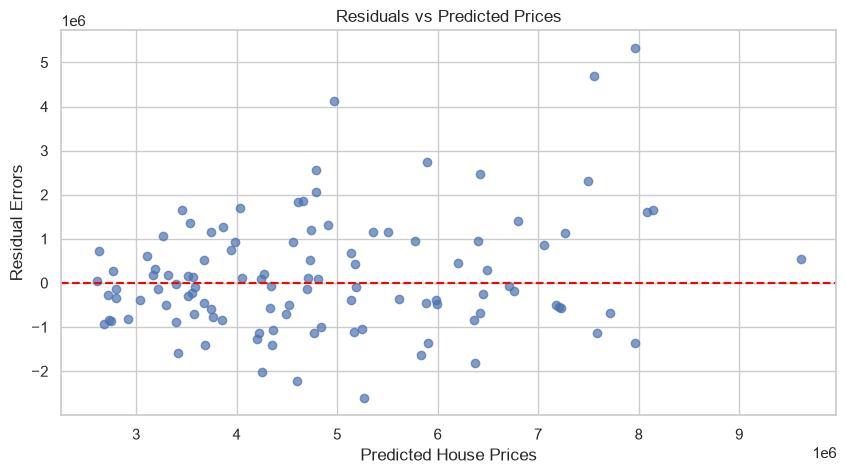

In [163]:
plt.figure(figsize=(10, 5))

plt.scatter(y_pred, residuals, alpha=0.7)

plt.axhline(y=0, color='red', linestyle='--')

plt.title("Residuals vs Predicted Prices")
plt.xlabel("Predicted House Prices")
plt.ylabel("Residual Errors")

plt.show()

**Observation:**

The residual plot illustrates the relationship between predicted house prices and prediction errors. The red dashed line represents zero error. Most data points are distributed around this line, indicating that the model produces both overestimations and underestimations. However, the residuals become more widely spread as predicted house prices increase. Some large positive and negative errors are also visible.

**Conclusion:** The increasing spread of residuals suggests possible heteroscedasticity, meaning that the prediction error variance is not constant across different price ranges. This indicates that the Linear Regression model may not fully capture all patterns in the housing data.

In [164]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

evaluation_results = pd.DataFrame({
    'Evaluation Metric': [
        'MAE',
        'MSE',
        'RMSE',
        'R2 Score'
    ],
    'Value': [
        mae,
        mse,
        rmse,
        r2
    ]
})

evaluation_results

,Evaluation Metric,Value
0,MAE,9.700434e+05
1,MSE,1.754319e+12
2,RMSE,1.324507e+06
3,R2 Score,6.529243e-01


### Model Evaluation – Observation

The Linear Regression model was evaluated using four performance metrics: MAE, MSE, RMSE and R² Score.

The model achieved an MAE of approximately 970,043.40 and an RMSE of approximately 1,324,507. The R² Score was 0.6529, indicating that the model explains approximately 65.29% of the variation in house prices on the testing dataset.

The results indicate that the model captures a reasonable portion of the relationship between property features and house prices. However, some prediction errors remain, suggesting opportunities for further improvement.

**Conclusion:** Linear Regression provides a useful baseline for house price prediction, but additional feature engineering and alternative machine learning algorithms could improve prediction performance.

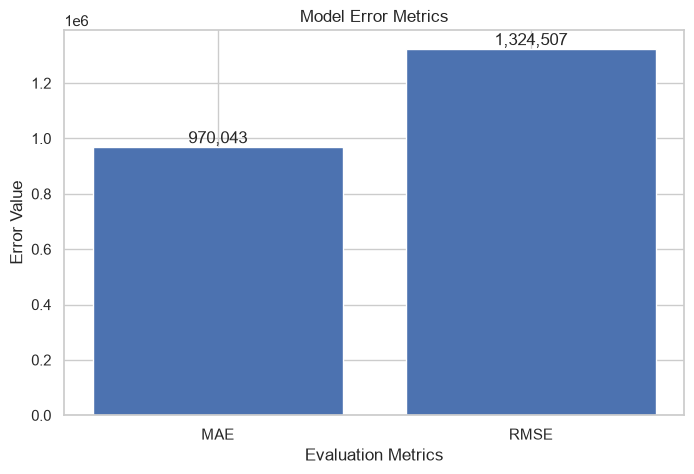

In [165]:
plt.figure(figsize=(8, 5))

bars = plt.bar(metrics.keys(), metrics.values())

plt.title("Model Error Metrics")
plt.ylabel("Error Value")
plt.xlabel("Evaluation Metrics")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f'{bar.get_height():,.0f}',
        ha='center',
        va='bottom'
    )

plt.show()

**Observation:**

The bar chart compares the Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) of the Linear Regression model. The MAE is approximately 970,043, while the RMSE is approximately 1,324,507. RMSE is higher than MAE because it gives greater importance to larger prediction errors.

**Conclusion:** The model produces prediction errors of varying magnitudes, and the difference between MAE and RMSE indicates the influence of larger errors on overall model performance.

In [166]:
# Select one house from testing data
sample_house = X_test.iloc[[0]]

# Predict house price
predicted_price = model.predict(sample_house)

# Get actual house price
actual_price = y_test.iloc[0]

print("Actual House Price:", actual_price)
print("Predicted House Price:", round(predicted_price[0], 2))

Actual House Price: 4060000
Predicted House Price: 5164653.9


**Observation:**

A sample property was selected from the testing dataset and provided to the trained Linear Regression model. The actual house price was 4,060,000, while the model predicted 5,164,653.90. The model overestimated the actual price by approximately 1,104,653.90. This demonstrates that the model can generate house price predictions, although some prediction differences remain.

**Conclusion:** The sample prediction demonstrates the practical application of the trained Linear Regression model. However, the prediction error indicates that the model can be further improved.

In [167]:
import joblib

joblib.dump(model, 'house_price_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [168]:
import os

print(
    "Model file exists:",
    os.path.exists('house_price_model.pkl')
)

Model file exists: True


# Final Project Conclusion

In this project, a House Price Prediction system was developed using the Linear Regression algorithm.

The dataset contained 545 records and 13 original columns. Exploratory Data Analysis (EDA) was performed to understand the relationships between property features and house prices.

Categorical variables were converted using One-Hot Encoding. The dataset was divided into 80% training data and 20% testing data.

The Linear Regression model achieved the following evaluation results:

- **MAE:** 970,043.40
- **MSE:** 1,754,318,687,330.66
- **RMSE:** 1,324,506.96
- **R² Score:** 0.6529 (65.29%)

The R² score indicates that the model explains approximately 65.29% of the variation in house prices in the testing dataset.

The project also included actual vs. predicted price visualization, residual analysis, coefficient analysis, sample prediction, and successful model saving using Joblib.

**Conclusion:** The project demonstrates the practical application of Linear Regression in predicting house prices based on property characteristics. The model provides a useful baseline, while further improvements using Ridge Regression, Lasso Regression, and feature engineering may improve prediction performance.